In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

from scipy.spatial import distance
import time
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Настройка визуального оформления графиков
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.autolayout'] = True

# Фиксируем random seed для детерминированности
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
def plot_distribution(series, ax=None, title_prefix="Распределение", color="royalblue"):
    """
    Универсальная функция: строит histplot с кривой KDE.
    Если ax=None, создает отдельное окно. Если ax передан, встраивается в сетку.
    """
    data = series.dropna()
    mean_val = data.mean()
    median_val = data.median()
    std_val = data.std()
    n = len(data)
    skew_val = data.skew()
    se_mean = std_val / np.sqrt(n)
    diff_ratio = abs(mean_val - median_val) / se_mean if se_mean > 0 else 0

    # ФЛАГ: запоминаем, создали ли мы ось сами
    own_ax = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(8.5, 4.5))
        own_ax = True # помечаем, что график одиночный

    # Отрисовка на оси ax
    sns.histplot(data, kde=True, color=color, bins=40, ax=ax, edgecolor="black", alpha=0.55)

    ax.axvline(mean_val, color="crimson", linestyle="--", linewidth=2, label=f"Среднее: {mean_val:.1f}")
    ax.axvline(median_val, color="darkgreen", linestyle="-", linewidth=2, label=f"Медиана: {median_val:.1f}")

    info_text = (f"Skewness: {skew_val:.2f}\n"
                f"Показатель (|x̄ - Me| / SE): {diff_ratio:.2f}\n")
    ax.text(
        0.97, 0.70, info_text, transform=ax.transAxes, fontsize=10,
        verticalalignment="top", horizontalalignment="right",
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="gray", alpha=0.85)
    )

    col_name = series.name if series.name else "Признак"
    ax.set_title(f"{title_prefix}: {col_name}")
    ax.set_xlabel(col_name)
    ax.set_ylabel("Частота")
    ax.legend(loc="upper right")

    # Если ось была создана внутри функции, сами красиво закрываем график
    if own_ax:
        plt.tight_layout()
        plt.show()
        
def manual_knn_impute(X_train, y_train, X_test, k=5, eps=1e-5):
    """
    Для каждого объекта с пропуском:
    - Считает Евклидово расстояние (L2) до всех известных объектов в один векторный проход.
    - Находит k ближайших соседей.
    - Рассчитывает веса: w_i = 1 / (d_i + eps). eps, чтобы не делили на 0
    - Возвращает взвешенное среднее таргета.
    X_train B: (N, D) - векторы с ЗАПОЛНЕННЫМИ target
    y_train: (N)   - известные нам таргеты
    X_test A:  (M, D) - векторы с НЕЗАПОЛНЕННЫМИ target
    вектор (M) - то, что мы хотим найти
    """
    # ХОТИМ получить C[i, j, k] = X_test[i, k] - X_train[j, k], k - признак
    # А(M, 1, D) - B(1, N, D) -> при вычитании они растягиваются до A(M, N, D) - B(M, N, D)
    # i соотносится с M, j соотносится с N, поэтому такая расстановка None
    diff = X_test[:, None, :] - X_train[None, :, :]

    # Суммируем по последней оси D -> получаем матрицу (M, N). axis=та, которая схлопнется суммой
    # sq_distances = r(X_test[i], X_train[j])
    # вычислим сумму квадратов разностей признаков
    sq_distances = np.sum(diff**2, axis=2)

    # для каждой строки X_test находим индексы k ближайших соседей X_train, хотим получить (M, k)
    # np.argpartition делает так, что элементы ДО k - меньше k, дальше - больше k
    # соседей можно искать по квадратам расстояний
    # вычисляем по axis=1 как здесь, так и дальше
    k_idx = np.argpartition(sq_distances, k, axis=1)[:, :k]

    # получаем (M, k) расстояний
    k_dists = np.sqrt(np.take_along_axis(sq_distances, k_idx, axis=1))

    # получаем (M, k) - матрицу таргетов для k ближайших точек для каждой строчки из X_test
    k_targets = y_train[k_idx]

    # взвешенное среднее
    weights = 1.0 / (k_dists + eps)
    imputed_values = np.sum(weights * k_targets, axis=1) / np.sum(weights, axis=1)
    return imputed_values

# Функция ручного расчета Евклидова расстояния (L2-норма)
def manual_euclidean(u, v):
    return np.sqrt(np.sum((u - v) ** 2))

# Функция ручного расчета Манхэттенского расстояния (L1-норма)
def manual_manhattan(u, v):
    return np.sum(np.abs(u - v))

# Функция ручного расчета расстояния Чебышёва (Max Distance)
def manual_chebyshev(u, v):
    return np.max(np.abs(u - v))

# Функция с матричными/векторными преобразованиями (NumPy broadcasting)
def vectorized_distances_to_all(X, query_point):
    """
    Вычисляет расстояния от одной точки query_point до всех N строк матрицы X
    в один проход без единого цикла for на уровне Python.
    X (N, D)
    query_point (1, D)
    """
    # размер (N, D) 
    # С[i, j] = X[i, j] - query_point[j] 
    diff = X - query_point  # Broadcasting: вектор вычитается из каждой строки параллельно
    
    # Манхэттенское расстояние (L1)
    l1_dists = np.sum(np.abs(diff), axis=1)
    
    # Евклидово расстояние (L2)
    l2_dists = np.sqrt(np.sum(diff ** 2, axis=1))
    
    # Расстояние Чебышёва (L_inf)
    linf_dists = np.max(np.abs(diff), axis=1)
    
    return l1_dists, l2_dists, linf_dists

# Функция расчета через обычный цикл for (невекторизованный подход)
def loop_distances_to_all(X, query_point):
    n_samples = len(X)
    l1_dists = np.empty(n_samples)
    l2_dists = np.empty(n_samples)
    linf_dists = np.empty(n_samples)
    
    for i in range(n_samples):
        row = X[i]
        l1_dists[i] = manual_manhattan(row, query_point)
        l2_dists[i] = manual_euclidean(row, query_point)
        linf_dists[i] = manual_chebyshev(row, query_point)
        
    return l1_dists, l2_dists, linf_dists

# Манхэттен через двойной цикл for (чистый Python)
def pairwise_manhattan_loops(X):
    n = len(X)
    dist_matrix = np.empty((n, n), dtype=float)
    for i in range(n):
        for j in range(n):
            # Ручной расчет L1-расстояния: сумма модулей разностей координат
            dist_matrix[i, j] = abs(X[i, 0] - X[j, 0]) + \
                                abs(X[i, 1] - X[j, 1]) + \
                                abs(X[i, 2] - X[j, 2])
    return dist_matrix

# Манхэттен через Broadcasting (NumPy)
def pairwise_manhattan_broadcasting(X):
    # X[:, 1, :] имеет форму (N, 1, D)
    # X[None, :, :] имеет форму (1, N, D)
    # При вычитании NumPy автоматически расширяет их до (N, N, D) без циклов for
    return np.abs(X[:, None, :] - X[None, :, :]).sum(axis=-1)

def manual_minmax_scaling(series: pd.Series) -> pd.Series:
    return (series - series.min()) / (series.max() - series.min())

def manual_z_scaling(series: pd.Series) -> pd.Series:
    return (series - series.mean()) / series.std()

In [3]:
# Загружаем датасет Airbnb и берём 45000 образцов 
df_global = pd.read_csv('data/diamonds.csv').drop(columns=["Unnamed: 0"])
print(f"Размер датасета: {df_global.shape}")
display(df_global.sample(8, random_state=RANDOM_STATE))

Размер датасета: (53940, 10)


,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61
1608,1.00,Fair,E,SI2,55.4,62.0,3011,6.63,6.59,3.66
46398,0.51,Ideal,F,VS1,60.2,56.0,1765,5.22,5.24,3.15
45493,0.52,Ideal,D,VS2,62.0,56.0,1679,5.17,5.19,3.21


### Основные характеристики
* **price** — Цена в долларах США ($326–$18,823).
* **carat** — Вес алмаза в каратах (0.2–5.01).

### Оценка качества (Характеристики «4C»)
* **cut** — Качество огранки. Порядок от худшего к лучшему: *Fair, Good, Very Good, Premium, Ideal*.
* **color** — Цвет алмаза. От **J** (худший, с оттенком) до **D** (лучший, бесцветный).
* **clarity** — Чистота/прозрачность камня. Порядок от худшего к лучшему: *I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF*.

### Размеры и пропорции
* **x** — Длина в мм (0–10.74).
* **y** — Ширина в мм (0–58.9).
* **z** — Глубина в мм (0–31.8).
* **depth** — Процент общей глубины. Формула: $2 \times z / (x + y)$ (43–79%).
* **table** — Ширина верхней площадки относительно самой широкой части камня в % (43–95%).


# 1. Метрики расстояния

In [4]:
# 1. Задаем исследуемые числовые признаки
features = ['carat', 'depth', 'table']

# 2. Выбираем 2 случайных алмаза
sample_df = df_global[features].sample(n=2, random_state=RANDOM_STATE)

print("--- Выбранные случайные алмазы (векторы в 3D) ---")
display(sample_df)

pt1 = sample_df.iloc[0].values.astype(float)
pt2 = sample_df.iloc[1].values.astype(float)

# 3. Расчёт расстояний готовыми функциями scipy
dist_l2_lib = distance.euclidean(pt1, pt2)
dist_l1_lib = distance.cityblock(pt1, pt2)
dist_linf_lib = distance.chebyshev(pt1, pt2)

print(f"\n--- Результаты библиотечных методов (scipy.spatial.distance) ---")
print(f"Евклидово расстояние (L2): {dist_l2_lib:.4f}")
print(f"Манхэттенское расстояние (L1): {dist_l1_lib:.4f}")
print(f"Расстояние Чебышёва (L_inf): {dist_linf_lib:.4f}")

--- Выбранные случайные алмазы (векторы в 3D) ---


,carat,depth,table
1388,0.24,62.1,56.0
50052,0.58,60.0,57.0



--- Результаты библиотечных методов (scipy.spatial.distance) ---
Евклидово расстояние (L2): 2.3507
Манхэттенское расстояние (L1): 3.4400
Расстояние Чебышёва (L_inf): 2.1000


In [5]:
# Проверяем вычисления на тех же точках
dist_l2_manual = manual_euclidean(pt1, pt2)
dist_l1_manual = manual_manhattan(pt1, pt2)
dist_linf_manual = manual_chebyshev(pt1, pt2)

print("--- Ручной расчёт (чистый Python без матричных операций) ---")
print(f"Евклидово (L2):   ручной = {dist_l2_manual:.4f} | scipy = {dist_l2_lib:.4f}")
print(f"Манхэттен (L1):   ручной = {dist_l1_manual:.4f} | scipy = {dist_l1_lib:.4f}")
print(f"Чебышёв (L_inf):  ручной = {dist_linf_manual:.4f} | scipy = {dist_linf_lib:.4f}")

--- Ручной расчёт (чистый Python без матричных операций) ---
Евклидово (L2):   ручной = 2.3507 | scipy = 2.3507
Манхэттен (L1):   ручной = 3.4400 | scipy = 3.4400
Чебышёв (L_inf):  ручной = 2.1000 | scipy = 2.1000


In [6]:
# Извлекаем числовую матрицу признаков всего датасета (45 000 x 3)
X_all = df_global[features].values.astype(float)
target_point = pt1  # целевая квартира, до которой ищем расстояния

# --- Сравнение скорости на 45 000 строках ---
print(f"Размер выборки для замера: {X_all.shape[0]} объектов\n")

# Замер цикла for
start_time = time.perf_counter()
res_loop = loop_distances_to_all(X_all, target_point)
time_loop = time.perf_counter() - start_time
print(f"1. Чистый цикл for по строкам:       {time_loop:.4f} сек.")

# Замер векторизации NumPy
start_time = time.perf_counter()
res_vec = vectorized_distances_to_all(X_all, target_point)
time_vec = time.perf_counter() - start_time
print(f"2. Матричные операции (NumPy):       {time_vec:.4f} сек.")

speedup = time_loop / time_vec
print(f"\nУскорение векторизации: в {speedup:.1f} раз быстрее!")

Размер выборки для замера: 53940 объектов

1. Чистый цикл for по строкам:       0.9982 сек.
2. Матричные операции (NumPy):       0.0028 сек.

Ускорение векторизации: в 355.8 раз быстрее!


In [7]:
is_needed = False
if is_needed:
    N_SAMPLE = 5000
    X_sub = df_global[features].dropna().values[:N_SAMPLE].astype(float)

    print(f"Размерность матрицы: {X_sub.shape[0]} объектов x {X_sub.shape[1]} признака")
    print(f"Количество попарных расстояний для расчета: {N_SAMPLE * N_SAMPLE:,}\n")

    # 1. Замеряем двойной цикл
    start_time = time.perf_counter()
    matrix_loops = pairwise_manhattan_loops(X_sub)
    time_loops = time.perf_counter() - start_time
    print(f"1. Двойной цикл for:              {time_loops:.4f} сек.")

    # 2. Замеряем бродкастинг
    start_time = time.perf_counter()
    matrix_broadcasting = pairwise_manhattan_broadcasting(X_sub)
    time_broadcasting = time.perf_counter() - start_time
    print(f"2. Broadcasting (матричный):      {time_broadcasting:.4f} сек.")

    speedup = time_loops / time_broadcasting
    print(f" Ускорение: векторный расчет быстрее в {speedup:.1f} раз!")

# Размерность матрицы: 5000 объектов x 3 признака
# Количество попарных расстояний для расчета: 25,000,000

# 1. Двойной цикл for:              19.9057 сек.
# 2. Broadcasting (матричный):      0.3430 сек.
#  Ускорение: векторный расчет быстрее в 58.0 раз!

# 2. Масштабирование

In [8]:
scale_cols = ['carat', 'table']

# 1. Наглядная проблема в цифрах (до масштабирования)
obj_a = sample_df.iloc[0][scale_cols]
obj_b = sample_df.iloc[1][scale_cols]

delta_carat_raw = obj_a['carat'] - obj_b['carat']
delta_table_raw = obj_a['table'] - obj_b['table']

sq_diff_carat_raw = delta_carat_raw ** 2
sq_diff_table_raw = delta_table_raw ** 2
total_sq_raw = sq_diff_carat_raw + sq_diff_table_raw

print("=== 1. РАСЧЕТ РАССТОЯНИЯ ДО МАСШТАБИРОВАНИЯ ===")
print(f"Разница по carat:          {delta_carat_raw:.2f}  | Квадрат разницы: {sq_diff_carat_raw:.4f}")
print(f"Разница по table:          {delta_table_raw:.2f}  | Квадрат разницы: {sq_diff_table_raw:.4f}")
print(f"Сумма квадратов разностей: {total_sq_raw:.4f}")
print(f"Доля вклада carat в итоговое расстояние: {sq_diff_carat_raw / total_sq_raw * 100:.6f}%")

df_scale_demo = df_global[scale_cols].copy()

# Ручной расчёт
df_scale_demo['carat_minmax_manual'] = manual_minmax_scaling(df_scale_demo['carat'])
df_scale_demo['table_minmax_manual'] = manual_minmax_scaling(df_scale_demo['table'])
df_scale_demo['carat_z_manual'] = manual_z_scaling(df_scale_demo['carat'])
df_scale_demo['table_z_manual'] = manual_z_scaling(df_scale_demo['table'])

# Расчёт через scikit-learn

# что здесь не так?

minmax_scaler = MinMaxScaler()
z_scaler = StandardScaler()
minmax_sk = minmax_scaler.fit_transform(df_global[scale_cols])
z_sk = z_scaler.fit_transform(df_global[scale_cols])

df_scale_demo['carat_minmax_sk'] = minmax_sk[:, 0]
df_scale_demo['table_minmax_sk'] = minmax_sk[:, 1]
df_scale_demo['carat_z_sk'] = z_sk[:, 0]
df_scale_demo['table_z_sk'] = z_sk[:, 1]

# 3. Пересчет расстояния ПОСЛЕ масштабирования
points_raw = sample_df.iloc[[0, 1]][scale_cols]
points_minmax = minmax_scaler.transform(points_raw)
points_z = z_scaler.transform(points_raw)

diff_mm = points_minmax[0] - points_minmax[1]
sq_mm = diff_mm ** 2
contrib_carat_mm = sq_mm[0] / np.sum(sq_mm) * 100

diff_z = points_z[0] - points_z[1]
sq_z = diff_z ** 2
contrib_carat_z = sq_z[0] / np.sum(sq_z) * 100

print("\n=== 2. ВКЛАД ПРИЗНАКА (CARAT) В РАССТОЯНИЕ ===")
print(f"Разница по carat z: {diff_z[0]:.2f}  | MinMax: {diff_mm[0]:.4f}")
print(f"Разница по table z: {diff_z[1]:.2f}  | MinMax: {diff_mm[1]:.4f}")
print(f"После Min-Max масштабирования: {contrib_carat_mm:.2f}%")
print(f"После Z-score стандартизации:  {contrib_carat_z:.2f}%")

=== 1. РАСЧЕТ РАССТОЯНИЯ ДО МАСШТАБИРОВАНИЯ ===
Разница по carat:          -0.34  | Квадрат разницы: 0.1156
Разница по table:          -1.00  | Квадрат разницы: 1.0000
Сумма квадратов разностей: 1.1156
Доля вклада carat в итоговое расстояние: 10.362137%

=== 2. ВКЛАД ПРИЗНАКА (CARAT) В РАССТОЯНИЕ ===
Разница по carat z: -0.72  | MinMax: -0.0707
Разница по table z: -0.45  | MinMax: -0.0192
После Min-Max масштабирования: 93.11%
После Z-score стандартизации:  71.98%


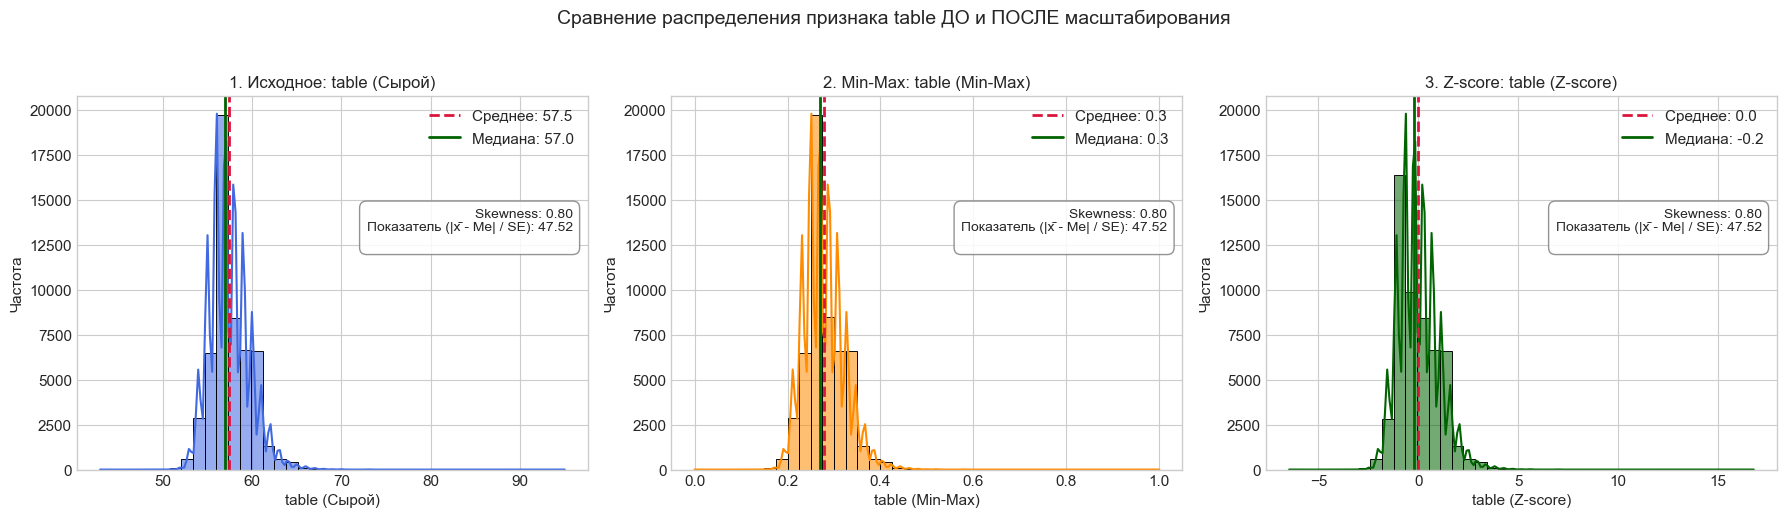

In [9]:
col_to_plot = 'table'

raw_series = df_scale_demo[col_to_plot]
raw_series.name = f'{col_to_plot} (Сырой)'

minmax_series = df_scale_demo[col_to_plot + "_minmax_sk"]
minmax_series.name = f'{col_to_plot} (Min-Max)'

z_series = df_scale_demo[col_to_plot + "_z_sk"]
z_series.name = f'{col_to_plot} (Z-score)'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_distribution(raw_series, ax=axes[0], title_prefix="1. Исходное", color="royalblue")
plot_distribution(minmax_series, ax=axes[1], title_prefix="2. Min-Max", color="darkorange")
plot_distribution(z_series, ax=axes[2], title_prefix="3. Z-score", color="darkgreen")

plt.suptitle(f"Сравнение распределения признака {col_to_plot} ДО и ПОСЛЕ масштабирования", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

# 3. Восстановление пропусков на основе расстояний (kNN-импутация)

In [10]:
# 1. Формируем эксперимент
df_scale_exp = df_global.copy()
target_col = 'carat'
feature_cols = ['x', 'price']

np.random.seed(RANDOM_STATE)
nan_indices = np.random.choice(df_scale_exp.index, size=1000, replace=False)

ground_truth = df_scale_exp.loc[nan_indices, target_col].values
df_scale_exp.loc[nan_indices, target_col] = np.nan

known_mask = df_scale_exp[target_col].notna()
y_known = df_scale_exp.loc[known_mask, target_col].values

# -------------------------------------------------------------
# 2. Вариант А: БЕЗ МАСШТАБИРОВАНИЯ (Сырые данные)
# -------------------------------------------------------------
X_known_raw = df_scale_exp.loc[known_mask, feature_cols].values
X_missing_raw = df_scale_exp.loc[nan_indices, feature_cols].values

pred_raw = manual_knn_impute(X_known_raw, y_known, X_missing_raw, k=5)
mae_raw = mean_absolute_error(ground_truth, pred_raw)

# -------------------------------------------------------------
# 3. Вариант Б: СО СТАНДАРТИЗАЦИЕЙ (StandardScaler)
# -------------------------------------------------------------
start_knn_scaled = time.perf_counter()
scaler = StandardScaler()
X_known_scaled = scaler.fit_transform(df_scale_exp.loc[known_mask, feature_cols])
X_missing_scaled = scaler.transform(df_scale_exp.loc[nan_indices, feature_cols])

pred_scaled = manual_knn_impute(X_known_scaled, y_known, X_missing_scaled, k=5)
mae_scaled = mean_absolute_error(ground_truth, pred_scaled)
time_knn = time.perf_counter() - start_knn_scaled

# -------------------------------------------------------------
# 4. Бейзлайн (Медиана трейна)
# -------------------------------------------------------------
med_val = np.median(y_known)
mae_med = mean_absolute_error(ground_truth, np.full(len(ground_truth), med_val))

# -------------------------------------------------------------
# 5. Вывод результатов
# -------------------------------------------------------------
print("=== ВЛИЯНИЕ СКЕЙЛИНГА НА k-NN ===")
print(f"Признаки: {feature_cols} -> Таргет: '{target_col}'\n")
print(f"1. k-NN БЕЗ масштабирования:    MAE = {mae_raw:.4f} карат")
print(f"2. Наивная медиана (Бейзлайн):   MAE = {mae_med:.4f} карат")
print(f"3. k-NN СО стандартизацией:     MAE = {mae_scaled:.4f} карат")

improvement = ((mae_raw - mae_scaled) / mae_raw) * 100
ratio = mae_raw / mae_scaled
print(f"\n-> Ошибка упала на {improvement:.1f}% (в {ratio:.1f} раз точнее!)")

=== ВЛИЯНИЕ СКЕЙЛИНГА НА k-NN ===
Признаки: ['x', 'price'] -> Таргет: 'carat'

1. k-NN БЕЗ масштабирования:    MAE = 0.0571 карат
2. Наивная медиана (Бейзлайн):   MAE = 0.3895 карат
3. k-NN СО стандартизацией:     MAE = 0.0208 карат

-> Ошибка упала на 63.6% (в 2.7 раз точнее!)


# 4. Корреляционный анализ и мультиколлинеарность

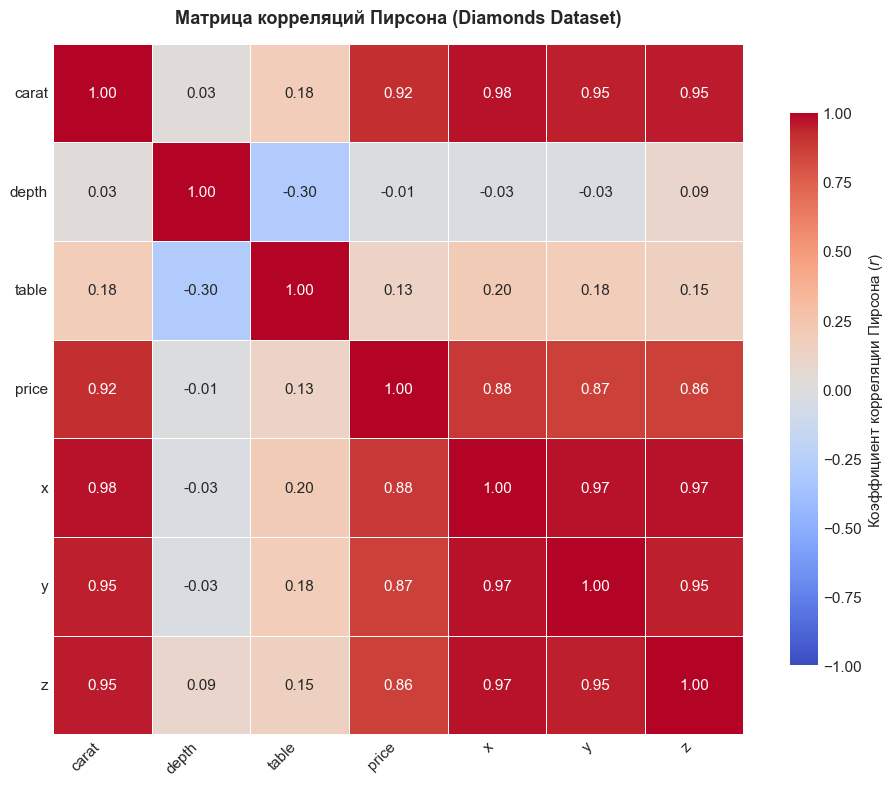

In [11]:
# 1. Отбираем только числовые признаки
numeric_cols = df_global.select_dtypes(include=[np.number]).columns.tolist()

# 2. Вычисляем матрицу линейной корреляции Пирсона
corr_matrix = df_global[numeric_cols].corr(method='pearson')

# 3. Визуализация в виде тепловой карты (Heatmap)
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Коэффициент корреляции Пирсона ($r$)"}
)

plt.title("Матрица корреляций Пирсона (Diamonds Dataset)", fontsize=13, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
# ТЕСТ: Неустойчивость на двух независимых подвыборках (по 1 000 алмазов)
sample_1 = df_global.sample(n=1000, random_state=42)
sample_2 = df_global.sample(n=1000, random_state=100)

# Однофакторная модель (только carat)
m1_carat = LinearRegression().fit(sample_1[['carat']], sample_1['price'])
m2_carat = LinearRegression().fit(sample_2[['carat']], sample_2['price'])

# Модель со всеми размерами
m1_multi = LinearRegression().fit(sample_1[['carat', 'x', 'y', 'z']], sample_1['price'])
m2_multi = LinearRegression().fit(sample_2[['carat', 'x', 'y', 'z']], sample_2['price'])

print("=== ТЕСТ 2: ОБУЧЕНИЕ НА ДВУХ СЛУЧАЙНЫХ ПОДВЫБОРКАХ (N=1000) ===")
print("1. Одиночный признак 'carat' (СТАБИЛЬНОСТЬ):")
print(f"   Сэмпл 1: w(carat) = {m1_carat.coef_[0]:8.2f}")
print(f"   Сэмпл 2: w(carat) = {m2_carat.coef_[0]:8.2f}")
print(f"   Разница:           {abs(m1_carat.coef_[0] - m2_carat.coef_[0]):8.2f} (веса практически идентичны)\n")

print("2. Мультиколлинеарный блок (ХАОС И НЕСТАБИЛЬНОСТЬ):")
for col, w1, w2 in zip(['carat', 'x', 'y', 'z'], m1_multi.coef_, m2_multi.coef_):
    print(f"   {col:5}: Сэмпл 1 = {w1:9.2f} | Сэмпл 2 = {w2:9.2f} | Разброс = {abs(w1 - w2):9.2f}")

=== ТЕСТ 2: ОБУЧЕНИЕ НА ДВУХ СЛУЧАЙНЫХ ПОДВЫБОРКАХ (N=1000) ===
1. Одиночный признак 'carat' (СТАБИЛЬНОСТЬ):
   Сэмпл 1: w(carat) =  7943.48
   Сэмпл 2: w(carat) =  7659.05
   Разница:             284.44 (веса практически идентичны)

2. Мультиколлинеарный блок (ХАОС И НЕСТАБИЛЬНОСТЬ):
   carat: Сэмпл 1 =  12238.07 | Сэмпл 2 =  10683.52 | Разброс =   1554.54
   x    : Сэмпл 1 =  -3326.85 | Сэмпл 2 =  -1131.28 | Разброс =   2195.57
   y    : Сэмпл 1 =   2885.18 | Сэмпл 2 =   1621.60 | Разброс =   1263.58
   z    : Сэмпл 1 =  -2324.89 | Сэмпл 2 =  -2892.16 | Разброс =    567.27


# 5. Регуляризация

In [13]:
# 1. Формируем выборку: таргет и блок с мультиколлинеарностью
features = ['carat', 'depth', 'table', 'x', 'y', 'z']
target = 'price'

X = df_global[features]
y = df_global[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE
)

# 2. МАСШТАБИРОВАНИЕ (критично для честного штрафа весов!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Инициализируем модели
# alpha — коэффициент силы штрафа
models = {
    'OLS (Без рег.)': LinearRegression(),
    'Ridge (L2)':      Ridge(alpha=100.0, random_state=RANDOM_STATE),
    'Lasso (L1)':      Lasso(alpha=25.0, random_state=RANDOM_STATE),
    'ElasticNet':      ElasticNet(alpha=0.5, l1_ratio=0.5, random_state=RANDOM_STATE)
}

weights_dict = {}
metrics_list = []

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    # Сохраняем веса для каждого признака
    weights_dict[name] = model.coef_
    
    # Считаем тестовые метрики качества
    metrics_list.append({
        'Модель': name,
        'MAE ($)': mean_absolute_error(y_test, y_pred),
        'R²': r2_score(y_test, y_pred),
        'Кол-во зануленных весов': np.sum(np.isclose(model.coef_, 0.0, atol=1e-3))
    })

# 4. Сводная таблица весов (стандартизированных коэффициентов)
df_weights = pd.DataFrame(weights_dict, index=features)
df_metrics = pd.DataFrame(metrics_list)

print("=== 1. СРАВНЕНИЕ ВЕСОВ ПРИЗНАКОВ (Standardized Coefficients) ===")
display(df_weights.style.format("{:10.2f}").background_gradient(cmap='coolwarm', axis=1))

print("\n=== 2. СРАВНЕНИЕ КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ ===")
display(df_metrics.style.format({
    'MAE ($)': '{:.2f}',
    'R²': '{:.4f}'
}))

=== 1. СРАВНЕНИЕ ВЕСОВ ПРИЗНАКОВ (Standardized Coefficients) ===


,OLS (Без рег.),Ridge (L2),Lasso (L1),ElasticNet
carat,5039.26,4715.85,3939.50,1421.69
depth,-285.98,-262.71,-186.19,-100.01
table,-230.38,-228.45,-192.44,-116.26
x,-1396.66,-1011.04,-237.70,780.24
y,37.09,6.18,-0.00,640.84
z,32.11,-6.81,-0.00,602.96



=== 2. СРАВНЕНИЕ КАЧЕСТВА НА ТЕСТОВОЙ ВЫБОРКЕ ===


,Модель,MAE ($),R²,Кол-во зануленных весов
0,OLS (Без рег.),885.27,0.8596,0
1,Ridge (L2),903.72,0.8590,0
2,Lasso (L1),962.07,0.8550,2
3,ElasticNet,1160.25,0.8166,0
